# Expermenting 

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from kinlens.metrics import Euclidean
from kinlens.search import BruteForseSearch
from kinlens.utils.dataset import DatasetBuilder
from kinlens.voting import InverseDistance

In [24]:
dataset = DatasetBuilder(Path("../samples/sample-larger.csv"), features=['feature_1', 'feature_2'], label='target')
dataset = dataset.build()

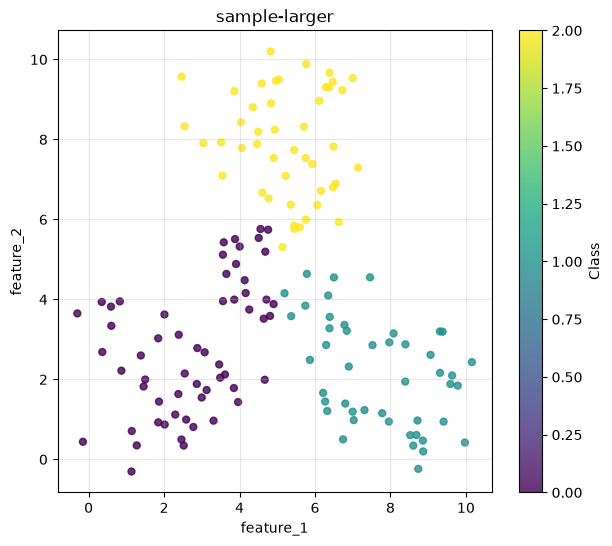

In [25]:
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    dataset.x[:, 0],
    dataset.x[:, 1],
    c=dataset.y,
    cmap="viridis",
    s=25,
    alpha=0.8,
)
plt.xlabel(dataset.features[0])
plt.ylabel(dataset.features[1])
plt.title(dataset.name)
plt.colorbar(scatter, label="Class")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
search = BruteForseSearch(metric=Euclidean())
search.fit(data=dataset)

In [5]:
searchResult = search.query(q=np.array([[1.2, 2.1]]), k=3)

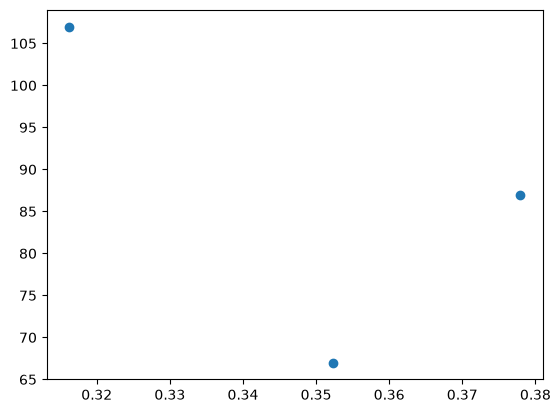

In [19]:
plt.scatter(searchResult.distances, searchResult.indices)

In [6]:
labels = dataset.y[searchResult.indices]

searchResult.distances

array([0.31624358, 0.35234642, 0.37791533])

In [7]:
voting = InverseDistance()

weights = voting.weight(searchResult)
weights

VotingResult(indices=array([107,  67,  87]), distances=array([0.31624358, 0.35234642, 0.37791533]), weights=array([3.16211956, 2.83811596, 2.64609533]))

In [23]:
result = search.query(np.array([5.0, 5.0]), k=5)

neighbor_labels = dataset.y[result.indices]
weights = voting.weight(result).weights

class_scores: dict[int, float] = {}

for label, weight in zip(neighbor_labels, weights):
    class_scores[int(label)] = class_scores.get(int(label), 0.0) + float(weight)

prediction: int = max(class_scores, key=class_scores.get)  # type: ignore[arg-type]

In [9]:
prediction

1

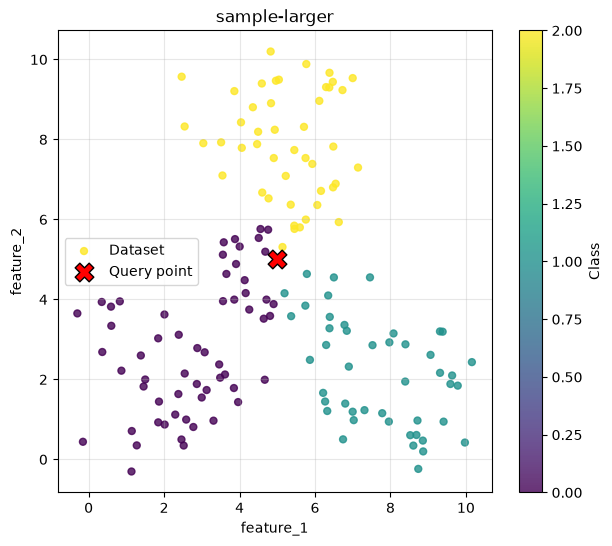

In [22]:
query_point = np.array([5.0, 5.0])

plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    dataset.x[:, 0],
    dataset.x[:, 1],
    c=dataset.y,
    cmap="viridis",
    s=25,
    alpha=0.8,
    label="Dataset",
)
plt.scatter(
    query_point[0],
    query_point[1],
    marker="X",
    s=180,
    c="red",
    edgecolors="black",
    label="Query point",
)
plt.xlabel(dataset.features[0])
plt.ylabel(dataset.features[1])
plt.title(dataset.name)
plt.colorbar(scatter, label="Class")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()